In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
df = pd.read_csv("Mall_Customers.csv")

print(df.head())
print(df.shape)
print(df.info())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [3]:
print(df.isnull().sum())

df = df.dropna()

print("Dataset after cleaning:")
print(df.shape)

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Dataset after cleaning:
(200, 5)


In [4]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print(X.head())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


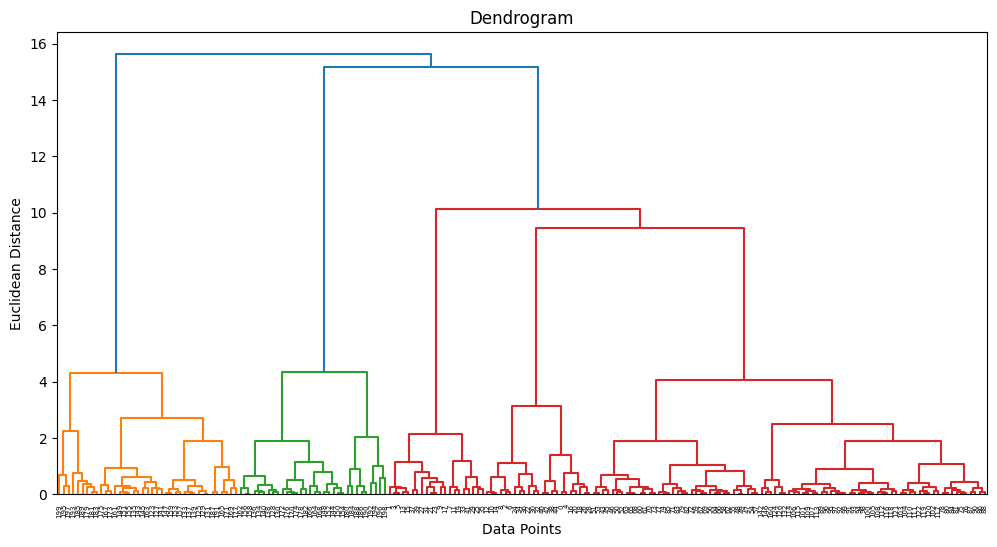

In [6]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(Z)

plt.title("Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

In [7]:
model = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

df['Cluster'] = model.fit_predict(X_scaled)

print(df.head(10))

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        4  
1        3  
2        4  
3        3  
4        4  
5        3  
6        4  
7        3  
8        4  
9        3  


In [8]:
print(df['Cluster'].value_counts())

Cluster
2    85
1    39
0    32
4    23
3    21
Name: count, dtype: int64


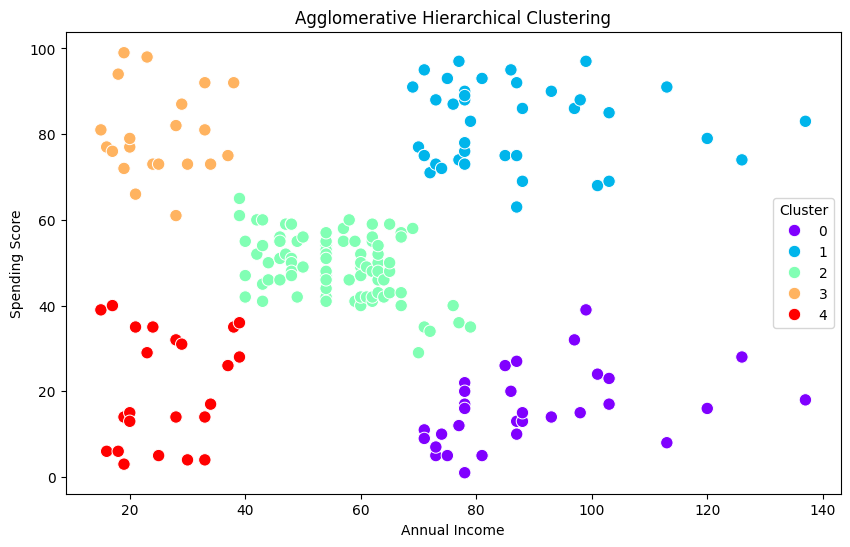

In [9]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=df['Cluster'],
    palette='rainbow',
    s=80
)

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

In [10]:
print("Cluster-wise Average:")

print(
    df.groupby('Cluster')[
        ['Annual Income (k$)', 'Spending Score (1-100)']
    ].mean()
)

Cluster-wise Average:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 89.406250               15.593750
1                 86.538462               82.128205
2                 55.811765               49.129412
3                 25.095238               80.047619
4                 26.304348               20.913043
